In [8]:
from pathlib import Path
dataset_path = Path("Dataset/dataset")

import numpy as np
import torch
import random

SEED = 42

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)

num_files = len(list(dataset_path.glob("*.png")))

print("Total PNG images:", num_files)

Total PNG images: 10710


## Viewing and looking at the dataset

In [9]:
files = [f.name for f in dataset_path.rglob("*") if f.is_file()]

unique_files = set(files)

print("Total files:", len(files))
print("Unique filenames:", len(unique_files))



Total files: 10713
Unique filenames: 10713


In [10]:
import re

In [11]:
classes = []

for file in dataset_path.glob("*.png"):
    filename = file.stem

    # Remove the number at the beginning
    filename = re.sub(r"^\d+\s+", "", filename)

    # Remove the image number and L/R at the end
    filename = re.sub(r"\s+\d+[LR]$", "", filename)

    classes.append(filename)

unique_classes = sorted(set(classes))

In [12]:
classes

['flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',
 'flat tile corner 2x2',


In [13]:
Class = []
for i in range(len(classes)):
    if classes[i] not in Class:
        Class.append(classes[i])

Class
    

['flat tile corner 2x2',
 'roof tile 1x2',
 'beam 1M',
 'brick corner 1x2x2',
 'plate corner 2x2',
 'Peg with friction',
 'flat tile round 2x2',
 'brick 2x4',
 'brick 2x3',
 'brick 2x2',
 'brick 1x2',
 'brick 1x1',
 'brick 1x4',
 'plate 2x4']

In [14]:
counter = 0
class_count = {}

for i in range(len(Class)):
    counter = 0
    for j in range(len(classes)):
        if classes[j] == Class[i]:
            counter += 1
    class_count[Class[i]]=counter

print(class_count)

{'flat tile corner 2x2': 800, 'roof tile 1x2': 800, 'beam 1M': 800, 'brick corner 1x2x2': 800, 'plate corner 2x2': 800, 'Peg with friction': 800, 'flat tile round 2x2': 800, 'brick 2x4': 800, 'brick 2x3': 800, 'brick 2x2': 800, 'brick 1x2': 800, 'brick 1x1': 800, 'brick 1x4': 800, 'plate 2x4': 310}


## Create CSV files to create a mapping of each image folder to it's corresponding label

In [15]:
import pandas as pd

data = {"class name": ["flat tile corner 2x2", "roof tile 1x2", "beam 1M", "brick corner 1x2x2", "plate corner 2x2", "Peg with friction", "flat tile round 2x2", "brick 2x4", "brick 2x3", "brick 2x2", "brick 1x2", "brick 1x1", "brick 1x4", "plate 2x4"],
       "Number of files in the class": [class_count["flat tile corner 2x2"], class_count["roof tile 1x2"], class_count["beam 1M"], class_count["brick corner 1x2x2"], class_count["plate corner 2x2"], class_count["Peg with friction"], class_count["flat tile round 2x2"], class_count["brick 2x4"], class_count["brick 2x3"], class_count["brick 2x2"], class_count["brick 1x2"], class_count["brick 1x1"], class_count["brick 1x4"], class_count["plate 2x4"]],
       "class ID":[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]}       
data                 

{'class name': ['flat tile corner 2x2',
  'roof tile 1x2',
  'beam 1M',
  'brick corner 1x2x2',
  'plate corner 2x2',
  'Peg with friction',
  'flat tile round 2x2',
  'brick 2x4',
  'brick 2x3',
  'brick 2x2',
  'brick 1x2',
  'brick 1x1',
  'brick 1x4',
  'plate 2x4'],
 'Number of files in the class': [800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  800,
  310],
 'class ID': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]}

In [16]:
import pandas as pd

data_samples = pd.DataFrame(data)
data_samples

,class name,Number of files in the class,class ID
0,flat tile corner 2x2,800,0
1,roof tile 1x2,800,1
2,beam 1M,800,2
3,brick corner 1x2x2,800,3
4,plate corner 2x2,800,4
5,Peg with friction,800,5
6,flat tile round 2x2,800,6
7,brick 2x4,800,7
8,brick 2x3,800,8
9,brick 2x2,800,9


In [17]:
data_samples.to_csv("dataset_mapping_1.csv", index=False)


In [18]:
files = []
for file in dataset_path.glob("*.png"):
    filename = str(file)
    files.append(str(filename))
    
class_match = []
for i in files:
    for j in Class:
        if j in i:
            class_match.append(j)
        
data = {"file name": files,
        "Class": class_match}

data_samples_2 = pd.DataFrame(data)
data_samples_2

,file name,Class
0,Dataset\dataset\14719 flat tile corner 2x2 000...,flat tile corner 2x2
1,Dataset\dataset\14719 flat tile corner 2x2 000...,flat tile corner 2x2
2,Dataset\dataset\14719 flat tile corner 2x2 001...,flat tile corner 2x2
3,Dataset\dataset\14719 flat tile corner 2x2 001...,flat tile corner 2x2
4,Dataset\dataset\14719 flat tile corner 2x2 002...,flat tile corner 2x2
...,...,...
10705,Dataset\dataset\3020 plate 2x4 152R.png,plate 2x4
10706,Dataset\dataset\3020 plate 2x4 153L.png,plate 2x4
10707,Dataset\dataset\3020 plate 2x4 153R.png,plate 2x4
10708,Dataset\dataset\3020 plate 2x4 154L.png,plate 2x4


In [19]:
class_mapping = dict(zip(
    data_samples["class name"],
    data_samples["class ID"]
))

data_samples_2["class ID"] = data_samples_2["Class"].map(class_mapping)
data_samples_2

,file name,Class,class ID
0,Dataset\dataset\14719 flat tile corner 2x2 000...,flat tile corner 2x2,0
1,Dataset\dataset\14719 flat tile corner 2x2 000...,flat tile corner 2x2,0
2,Dataset\dataset\14719 flat tile corner 2x2 001...,flat tile corner 2x2,0
3,Dataset\dataset\14719 flat tile corner 2x2 001...,flat tile corner 2x2,0
4,Dataset\dataset\14719 flat tile corner 2x2 002...,flat tile corner 2x2,0
...,...,...,...
10705,Dataset\dataset\3020 plate 2x4 152R.png,plate 2x4,13
10706,Dataset\dataset\3020 plate 2x4 153L.png,plate 2x4,13
10707,Dataset\dataset\3020 plate 2x4 153R.png,plate 2x4,13
10708,Dataset\dataset\3020 plate 2x4 154L.png,plate 2x4,13


In [20]:
data_samples_2.to_csv("dataset_mapping_2.csv", index=False)

## Visualise the data

In [21]:
from PIL import Image

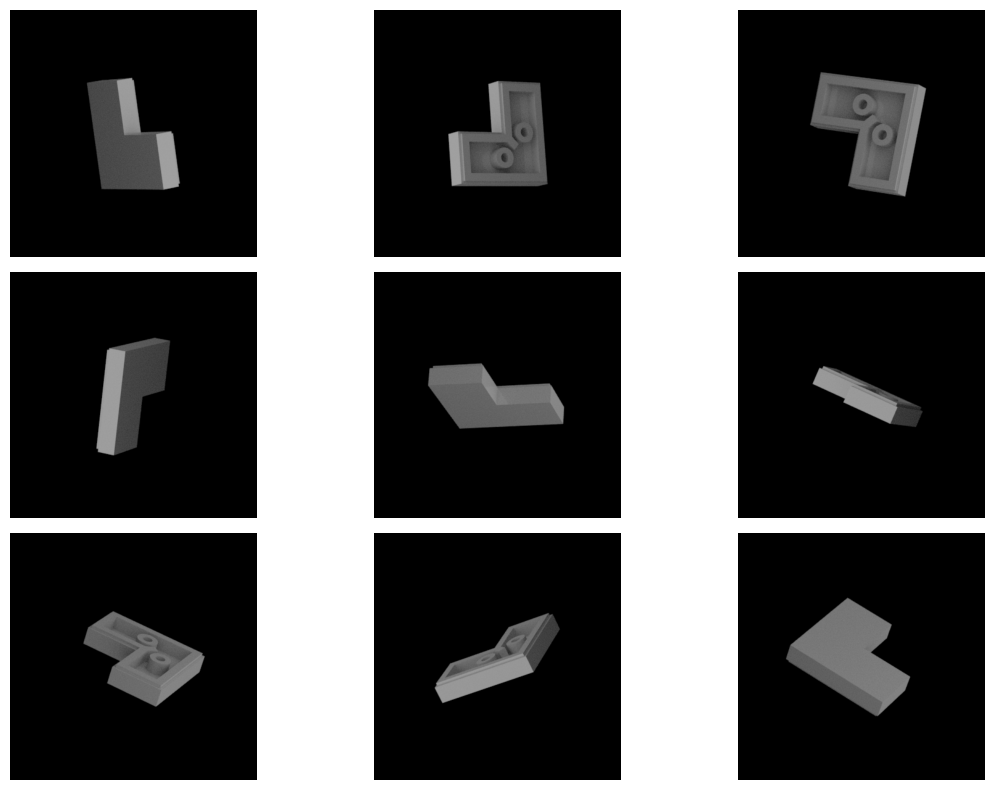

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 3, figsize=(12, 8))

for ax, filename in zip(axes.flat, data_samples_2["file name"].head(9)):
    image = Image.open(filename).convert("RGB")
    ax.imshow(image)
    #ax.set_title(filename, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
%%writefile customDataset.py
import pandas as pd
import torch
from torch.utils.data import Dataset
from torchvision.io import decode_image

class customDataset(Dataset):
    def __init__(self, annotation_file, transform=None, target_transform=None):
        
        self.img_labels = pd.read_csv(annotation_file)
        
        self.transform = transform
        
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):

        # Get image path
        img_path = self.img_labels.iloc[idx]["file name"]

        # Load PNG image
        image = decode_image(str(img_path), mode="RGB")

        # Get numerical class ID
        label = int(self.img_labels.iloc[idx]["class ID"])

        if self.transform:
            image = self.transform(image)

        if self.target_transform:
            label = self.target_transform(label)

        return image, label

Overwriting customDataset.py


In [25]:
import torch
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.CenterCrop(224),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
transform

target_transform = data_samples["class ID"]

In [26]:
from customDataset import customDataset
legoBrickDataset = customDataset(annotation_file="dataset_mapping_2.csv", transform=transform)

## Create a 20% version of the dataset for testing and choosing the best model 

In [27]:
import pandas as pd
csv = pd.read_csv("dataset_mapping_2.csv")

dataset = csv.sample(frac=1, random_state=42).reset_index(drop=True)


In [28]:
torch.cuda.manual_seed(42)
subset_size = int(len(dataset) * 0.2)

while True:
    # Randomly select 20% of the dataset
    csv_20 = dataset.sample(n=subset_size, random_state=42).copy()

    counter = 0
    numclass = []

    for i in range(len(Class)):
        for j in range(len(csv_20["Class"])):
            if Class[i] == csv_20["Class"].iloc[j]:
                counter += 1

        numclass.append(counter)
        counter = 0

    # Check if every class has at least one sample
    if all(count > 0 for count in numclass):
        print("All classes have at least 1 data sample")
        break
    else:
        print("Some classes have 0 samples. Reshuffling...")

print("Original dataset:", len(dataset))
print("20% subset size:", len(csv_20))
print("Samples per class:", csv_20["Class"].value_counts())

All classes have at least 1 data sample
Original dataset: 10710
20% subset size: 2142
Samples per class: Class
brick 2x4               187
beam 1M                 180
brick 2x3               175
brick 1x1               165
brick 2x2               164
flat tile corner 2x2    162
brick 1x4               162
brick 1x2               159
Peg with friction       154
brick corner 1x2x2      154
plate corner 2x2        151
roof tile 1x2           143
flat tile round 2x2     125
plate 2x4                61
Name: count, dtype: int64


In [29]:
csv_20.to_csv("data_mapping_20percent.csv", index=False)

In [30]:
legoBrickDataset_20 = customDataset(annotation_file="data_mapping_20percent.csv", transform=transform)

In [31]:
print(type(legoBrickDataset_20))

<class 'customDataset.customDataset'>


In [32]:
import torch
from torch.utils.data import Subset

# Shuffle dataset indices
shuffled_indices = torch.randperm(
    len(legoBrickDataset_20)
).tolist()

# Create shuffled dataset
shuffle_data = Subset(legoBrickDataset_20, shuffled_indices)

# 80/20 split
train_size = int(0.8 * len(shuffle_data))

train = Subset(shuffle_data, range(train_size))
test = Subset(shuffle_data, range(train_size, len(shuffle_data)))

print(len(train), len(test))

1713 429


In [33]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train, batch_size=32, shuffle=True)

test_dataloader = DataLoader(test, batch_size=32, shuffle=True)


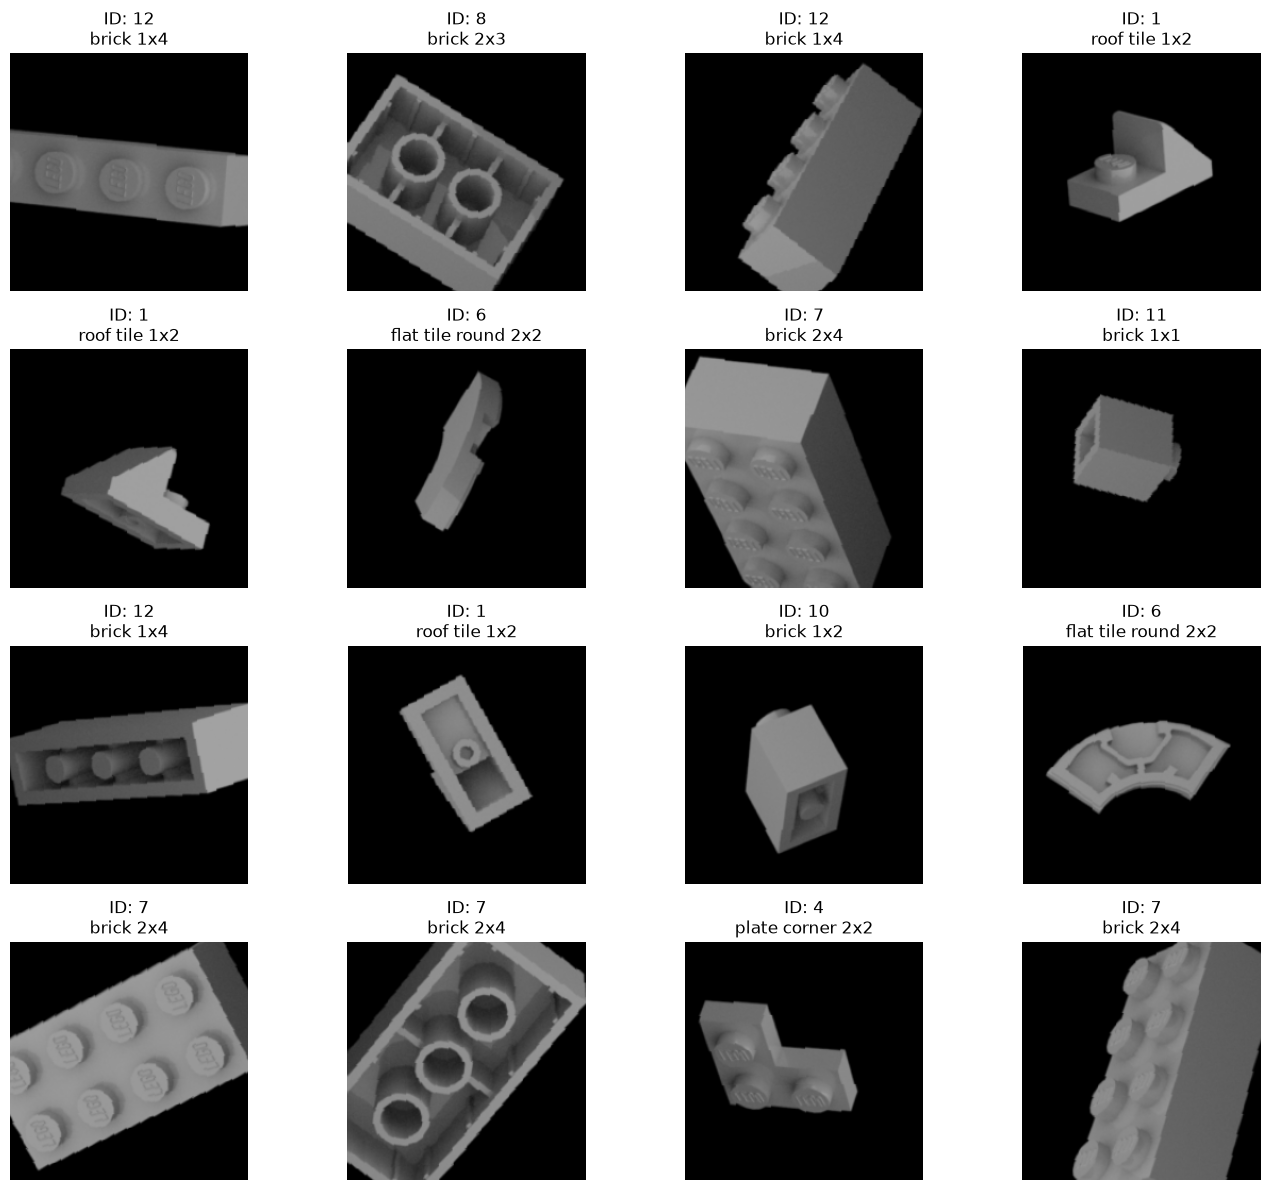

In [37]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import random

train_features, train_labels = next(iter(train_dataloader))

#print(f"Feature batch shape: {train_features.shape}")
#print(f"Labels batch shape: {train_labels.shape}")

# Load CSV class mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

# Get a batch from the dataloader
X, y = next(iter(test_dataloader))

# Select 16 random images from the batch
indices = random.sample(range(len(X)), min(16, len(X)))

# Values for reversing normalisation
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 4, figsize=(14, 12))

for ax in axes.flatten():
    ax.axis("off")

for ax, idx in zip(axes.flatten(), indices):

    image = X[idx].cpu()
    label = y[idx].item()

    # Find the class name from the CSV
    class_name = look_up_value.loc[
        look_up_value["class ID"] == label,
        "class name"
    ].iloc[0]

    # Reverse normalisation for display
    image = image * std + mean
    image = image.clamp(0, 1)

    # Display image and assigned label
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f"ID: {label}\n{class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [38]:
random.seed(42)
import torch
from torch.utils.data import Dataset
from collections import Counter
import random

# Get all training labels
labels = train_labels

# Count samples per class
class_counts = Counter(labels)

# Find the largest class
max_count = max(class_counts.values())

# Store indices for each class
class_indices = {}

for idx, label in enumerate(labels):
    class_indices.setdefault(label, []).append(idx)

# Oversample each class to the same size
balanced_indices = []

for label, indices in class_indices.items():
    balanced_indices.extend(indices)

    extra_indices = random.choices(
        indices,
        k=max_count - len(indices)
    )

    balanced_indices.extend(extra_indices)

random.shuffle(balanced_indices)
print (balanced_indices)

[26, 5, 10, 15, 25, 11, 22, 6, 19, 12, 16, 9, 28, 14, 24, 20, 30, 1, 13, 18, 2, 17, 21, 3, 29, 4, 27, 31, 8, 23, 0, 7]


## Build CNN

In [ ]:
import torch.nn as nn

class legoClassifierv1(nn.Module):
    def __init__(self, input_size, hidden_unit, output_size):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_channels=input_size, out_channels=hidden_unit, kernel_size=3, padding=1),
                                  nn.ReLU(),
                                  nn.MaxPool2d(kernel_size=2, stride=3),
                                  nn.Conv2d(in_channels=hidden_unit, out_channels=hidden_unit, kernel_size=3, padding=1),
                                  nn.ReLU(),
                                  nn.MaxPool2d(kernel_size=2, stride=3),
                                  nn.Conv2d(in_channels=hidden_unit, out_channels=hidden_unit, kernel_size=3, padding=1),
                                  nn.ReLU(),
                                  nn.AdaptiveAvgPool2d((1, 1))
                                 )

        self.dense = nn.Sequential(nn.Flatten(),
                                   nn.LazyLinear(out_features=50),
                                   nn.ReLU(),
                                   nn.Linear(in_features=50, out_features=output_size))
                                   

    def forward(self, x):
        x = self.conv(x)
        x = self.dense(x)
        return x

device = "cuda" if torch.cuda.is_available() else "cpu"
model_0 = legoClassifierv1(3, 64, len(Class))
model_0 = model_0.to(device)
model_0
        

## train CNN model

In [ ]:
loss_function = nn.CrossEntropyLoss()

optim = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

In [54]:
from tqdm.auto import tqdm
from torch.utils.tensorboard import SummaryWriter

def train_loop(model:nn.Module, epoch:int, batch:int, loss_fn, optimizer, train_dataloader, test_dataloader):
    torch.cuda.manual_seed(42)
    
    EPOCH = epoch
    BATCH_SIZE = batch
    
    #list for storing loss and accuracy in the list per epoch to plot loss and accuracy
    train_loss_list = []
    train_acc_list = []
    test_loss_list = []
    test_acc_list = []
    epoch_list = []
    
    for epochs in tqdm(range(EPOCH)):
        model.train()
    
        train_loss = 0
        train_acc = 0
        test_loss = 0
        test_correct = 0
        test_total = 0
    
        # split dataloader into X and y
        for batch, (X, y) in enumerate(train_dataloader):
            X = X.to(device)
            y = y.to(device)
    
            #forward pass
            y_pred = model(X)# y_preds is y_logits
    
            #calculate loss
            loss = loss_fn(y_pred, y)
    
            #reset gradients
            optimizer.zero_grad()
    
            #back propagation
            loss.backward()
    
            #update weights
            optimizer.step()
    
            # Track loss and accuracy
            train_loss += loss.item() * X.size(0)
            train_acc += (y_pred.argmax(dim=1) == y).sum().item()
    
        model.eval()
    
        with torch.inference_mode():  
            for X, y in test_dataloader:
                X = X.to(device)
                y = y.to(device)
        
                y_logits = model(X)
                y_pred = y_logits.argmax(dim=1)
        
                # Calculate batch loss
                loss = loss_fn(y_logits, y)
                
                # Track loss and accuracy
                test_loss += loss.item() * X.size(0)
                test_correct += (y_pred == y).sum().item()
                test_total += y.size(0)
    
        test_loss /= test_total
        test_acc = test_correct / test_total * 100
    
        test_loss_list.append(test_loss)
        test_acc_list.append(test_acc)
    
        train_loss /= len(train_dataloader.dataset)
        train_acc = train_acc / len(train_dataloader.dataset) * 100
    
        train_loss_list.append(train_loss)
        train_acc_list.append(train_acc)
    
        epoch_list.append(epochs+1)
        
        print(f"Epoch: {epochs+1}/{EPOCH} | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}% | Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")
    
    return {
        "epoch": epoch_list,
        "train_loss": train_loss_list,
        "train_acc": train_acc_list,
        "test_loss": test_loss_list,
        "test_acc": test_acc_list
    }
    
"""model_0_train = train_loop(model=model_0,
                           epoch=5,
                           batch=32,
                           loss_fn=loss_function,
                           optimizer=optim,
                           train_dataloader=train_dataloader,
                           test_dataloader=test_dataloader)"""

'model_0_train = train_loop(model=model_0,\n                           epoch=5,\n                           batch=32,\n                           loss_fn=loss_function,\n                           optimizer=optim,\n                           train_dataloader=train_dataloader,\n                           test_dataloader=test_dataloader)'

## visualise the resault

In [ ]:
import matplotlib.pyplot as plt

def plot_loss_curve(loss_title, acc_title, train_acc, test_acc, train_loss, test_loss, epoch):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: Loss
    ax[0].plot(epoch, train_loss, label="Train Loss")
    ax[0].plot(epoch, test_loss, label="Test Loss")
    
    ax[0].set_title(loss_title)
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()
    ax[0].grid(True)
    
    # Subplot 2: Accuracy
    ax[1].plot(epoch, train_acc, label="Train Accuracy")
    ax[1].plot(epoch, test_acc, label="Test Accuracy")
    
    ax[1].set_title(acc_title)
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy (%)")
    ax[1].legend()
    ax[1].grid(True)
    
    plt.tight_layout()
    plt.show()

plot_loss_curve(
    loss_title="Custom CNN Loss",
    acc_title = "Custom CNN Accuracy",
    train_acc=model_0_train["train_acc"],
    test_acc=model_0_train["test_acc"],
    train_loss=model_0_train["train_loss"],
    test_loss=model_0_train["test_loss"],
    epoch=model_0_train["epoch"]
)

## Try it with ResNet18

In [ ]:
from torchvision import models
from torch import nn

weights = models.ResNet18_Weights.DEFAULT

model_1 = models.resnet18(weights=weights)


## Freeze layer

In [ ]:
from torchinfo import summary

for param in model_1.parameters():
    param.requires_grad=False

model_1.fc = nn.Linear(
    in_features=model_1.fc.in_features,
    out_features=14
)

model_1 = model_1.to(device)

summary(model_1, 
        input_size=(1, 3, 224, 224), 
        col_names=["input_size","output_size","num_params","trainable"],
        col_width=20,
        depth=2,
        device=device)

## train resnet with lego dataset

In [ ]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_1.fc.parameters(),
    lr=0.001
)

model_1_train = train_loop(model=model_1,
                           epoch=5,
                           batch=32,
                           loss_fn=loss_function,
                           optimizer=optimizer,
                           train_dataloader=train_dataloader,
                           test_dataloader=test_dataloader)

## plot loss and accuracy

In [ ]:
plot_loss_curve(loss_title="ResNet18 Loss",
                acc_title="ResNet18 Accuracy(%)",
                train_acc = model_1_train["train_acc"],
                test_acc = model_1_train["test_acc"],
                train_loss = model_1_train["train_loss"],
                test_loss = model_1_train["test_loss"],
                epoch = model_1_train["epoch"])


## As ResNet is the best model with the best accuracy rate(for now), therefore it is chosen to train with 20 epochs

In [ ]:
from torchvision import models
from torch import nn

weights = models.ResNet18_Weights.DEFAULT

best_model = models.resnet18(weights=weights)


for param in best_model.parameters():
    param.requires_grad=False

best_model.fc = nn.Linear(in_features=best_model.fc.in_features,
    out_features=14
)

best_model = best_model.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=best_model.parameters(), lr=0.0001)
                             
resnet18_results = train_loop(model=best_model,
                        epoch=20,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
plot_loss_curve(loss_title="ResNet18 with 20 epochs Loss",
                acc_title = "Resnet18 with 20 epochs Accuracy(%)",
                train_acc = resnet18_results["train_acc"],
                test_acc = resnet18_results["test_acc"],
                train_loss = resnet18_results["train_loss"],
                test_loss = resnet18_results["test_loss"],
                epoch = resnet18_results["epoch"])

## Load and save ResNet model weights

In [ ]:
if Path("models/resnet18_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(best_model.state_dict(), "models/resnet18_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(best_model.state_dict(), "models/resnet18_model.pth")
    print ("saving model ...")

In [ ]:
# Recreate ResNet18 architecture
device = "cuda" if torch.cuda.is_available else "cpu"

loaded_model = models.resnet18(weights=None)

loaded_model = loaded_model.to(device)

# Recreate the classification layer
loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    14
)

loaded_model.fc.to(device)

# Load all saved weights
loaded_model.load_state_dict(
    torch.load(
        "models/resnet18_model.pth",
        weights_only=True
    )
)

loaded_model.eval()

In [ ]:
from PIL import Image

image = Image.open("brick.jpg").convert("RGB")

display(image)

In [ ]:
from torchvision import transforms

predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = predict_transform(image)

image_tensor = image_tensor.unsqueeze(0)

image_tensor = image_tensor.to(device)

print(image_tensor.shape)
print(image_tensor.device)

In [ ]:
loaded_model.eval()

with torch.inference_mode():
    logits = loaded_model(image_tensor).to(device)

    probabilities = torch.softmax(logits, dim=1)

    predicted_class = probabilities.argmax(dim=1).item()

    confidence = probabilities.max(dim=1).values.item()



In [ ]:
look_up_value = pd.read_csv("dataset_mapping_1.csv")
look_up_value

In [ ]:
predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")

## The model was not very confident. try it with more epochs

In [ ]:
from torchvision import models
from torch import nn

weights = models.ResNet18_Weights.DEFAULT

model_2 = models.resnet18(weights=weights)

for param in model_2.parameters():
    param.requires_grad=False

model_2.fc = nn.Linear(in_features=best_model.fc.in_features,
    out_features=14
)

model_2 = model_2.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_2.parameters(), lr=0.0001)
                             
model_2_results = train_loop(model=model_2,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
plot_loss_curve(loss_title="ResNet18 with 50 epochs Loss",
                acc_title = "Resnet18 with 50 epochs Accuracy(%)",
                train_acc = model_2_results["train_acc"],
                test_acc = model_2_results["test_acc"],
                train_loss = model_2_results["train_loss"],
                test_loss = model_2_results["test_loss"],
                epoch = model_2_results["epoch"])

In [ ]:
from PIL import Image

image = Image.open("brick.jpg").convert("RGB")

model_2.eval()
from torchvision import transforms

predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = predict_transform(image)

image_tensor = image_tensor.unsqueeze(0)

image_tensor = image_tensor.to(device)

print(image_tensor.shape)
print(image_tensor.device)

In [ ]:

with torch.inference_mode():
    logits = model_2(image_tensor).to(device)

    probabilities = torch.softmax(logits, dim=1)

    predicted_class = probabilities.argmax(dim=1).item()

    confidence = probabilities.max(dim=1).values.item()

In [ ]:
look_up_value = pd.read_csv("dataset_mapping_1.csv")

predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")

In [ ]:
from sklearn.metrics import classification_report
import torch

def evaluate_model(model, dataloader, device, class_names=None):
    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for X, y in dataloader:
            X = X.to(device)
            y = y.to(device)

            # Forward pass
            y_logits = model(X)

            # Convert logits to predicted class IDs
            predictions = y_logits.argmax(dim=1)

            # Store actual and predicted labels
            y_true.extend(y.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    # Generate classification report
    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))) if class_names is not None else None,
        target_names=class_names,
        zero_division=0
    ))

In [ ]:
evaluate_model(
    model=model_2,
    dataloader=test_dataloader,
    device=device,
    class_names=Class
)

In [ ]:
if Path("models/resnet18_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(best_model.state_dict(), "models/resnet18_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(best_model.state_dict(), "models/resnet18_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
device = "cuda" if torch.cuda.is_available else "cpu"

loaded_model = models.resnet18(weights=None)

loaded_model = loaded_model.to(device)

# Recreate the classification layer
loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    14
)

loaded_model.fc.to(device)

# Load all saved weights
loaded_model.load_state_dict(
    torch.load(
        "models/resnet18_50_epoch_model.pth",
        weights_only=True
    )
)

loaded_model.eval()

with torch.inference_mode():
    logits = loaded_model(image_tensor).to(device)

    probabilities = torch.softmax(logits, dim=1)

    predicted_class = probabilities.argmax(dim=1).item()

    confidence = probabilities.max(dim=1).values.item()

look_up_value = pd.read_csv("dataset_mapping_1.csv")

predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")

## Try ResNet50 to see if it can get a better result

In [ ]:
from torchvision import models
from torch import nn

weights = models.ResNet50_Weights.DEFAULT

model_3 = models.resnet50(weights=weights)

for param in model_3.parameters():
    param.requires_grad=False

model_3.fc = nn.Linear(in_features=model_3.fc.in_features,
    out_features=14
)

model_3 = model_3.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_3.parameters(), lr=0.0001)
                             
model_3_results = train_loop(model=model_3,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
plot_loss_curve(loss_title="ResNet50 with 50 epochs Loss",
                acc_title = "Resnet50 with 50 epochs Accuracy(%)",
                train_acc = model_3_results["train_acc"],
                test_acc = model_3_results["test_acc"],
                train_loss = model_3_results["train_loss"],
                test_loss = model_3_results["test_loss"],
                epoch = model_3_results["epoch"])

In [ ]:
evaluate_model(
    model=model_3,
    dataloader=test_dataloader,
    device=device,
    class_names=Class
)

In [ ]:
if Path("models/resnet50_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_3.state_dict(), "models/resnet50_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_3.state_dict(), "models/resnet50_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
import torch
from torch import nn
from torchvision import models
import pandas as pd

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create ResNet50
resnet50_loaded_model = models.resnet50(weights=None)

# Recreate the classification layer
resnet50_loaded_model.fc = nn.Linear(
    in_features=resnet50_loaded_model.fc.in_features,
    out_features=14
)

# Move entire model to device
resnet50_loaded_model = resnet50_loaded_model.to(device)

# Load saved weights
state_dict = torch.load(
    "models/resnet50_50_epoch_model.pth",
    map_location=device,
    weights_only=True
)

resnet50_loaded_model.load_state_dict(state_dict)

# Evaluation mode
resnet50_loaded_model.eval()

# Get images and labels
X, y = next(iter(test_dataloader))

# Select one image
image_tensor = X[0].unsqueeze(0).to(device)

# Ground truth
y_true = y[0].item()

# Generate prediction
resnet50_loaded_model.eval()

with torch.inference_mode():
    logits = resnet50_loaded_model(image_tensor)

    probabilities = torch.softmax(logits, dim=1)

    confidence, predicted_class = probabilities.max(dim=1)

    predicted_class = predicted_class.item()
    confidence = confidence.item()

# Load class mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

resnet50_loaded_model.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = resnet50_loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

## It was pretty good. Try to experiment with EffNetB0 as well

In [ ]:
from torchvision import models
from torch import nn

weights = models.EfficientNet_B0_Weights.DEFAULT

model_4 = models.efficientnet_b0(weights=weights)

for param in model_4.parameters():
    param.requires_grad=False

# Replace classifier with 14 LEGO classes
model_4.classifier[1] = nn.Linear(
in_features=model_4.classifier[1].in_features,
out_features=14
)

model_4 = model_4.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_4.parameters(), lr=0.0001)
                             
model_4_results = train_loop(model=model_4,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
plot_loss_curve(loss_title="EfficientNet_B0 with 50 epochs Loss",
                acc_title = "EfficientNet_B0 with 50 epochs Accuracy(%)",
                train_acc = model_4_results["train_acc"],
                test_acc = model_4_results["test_acc"],
                train_loss = model_4_results["train_loss"],
                test_loss = model_4_results["test_loss"],
                epoch = model_4_results["epoch"])

In [ ]:
evaluate_model(
    model=model_4,
    dataloader=test_dataloader,
    device=device,
    class_names=Class
)

In [ ]:
if Path("models/EfficientnetB0_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_4.state_dict(), "models/EfficientnetB0_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_4.state_dict(), "models/EfficientnetB0_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
import torch
from torch import nn
from torchvision import models
import pandas as pd

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create EfficientNet-B0
loaded_model = models.efficientnet_b0(weights=None)

# Recreate the classification layer for 14 classes
loaded_model.classifier[1] = nn.Linear(
    in_features=loaded_model.classifier[1].in_features,
    out_features=14
)

# Move model to device
loaded_model = loaded_model.to(device)

# Load saved weights
state_dict = torch.load(
    "models/EfficientnetB0_50_epoch_model.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(state_dict)

# Evaluation mode
loaded_model.eval()

# Get images and labels
X, y = next(iter(test_dataloader))

# Select one image
image_tensor = X[0].unsqueeze(0).to(device)

# Ground truth
y_true = y[0].item()

# Generate prediction
with torch.inference_mode():
    logits = loaded_model(image_tensor)

    probabilities = torch.softmax(logits, dim=1)

    confidence, predicted_class = probabilities.max(dim=1)

    predicted_class = predicted_class.item()
    confidence = confidence.item()

# Load class mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

# Predicted LEGO class name
predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

# Actual LEGO class name
actual_name = look_up_value.loc[
    look_up_value["class ID"] == y_true,
    "class name"
].iloc[0]

print("Actual LEGO brick:", actual_name)
print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")
print("Correct prediction:", predicted_class == y_true)

In [ ]:
import matplotlib.pyplot as plt

# Image is normalized, so reverse ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image_display = X[0].cpu() * std + mean
image_display = image_display.clamp(0, 1)

plt.imshow(image_display.permute(1, 2, 0))
plt.title("LEGO image being predicted")
plt.axis("off")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

loaded_model.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

## Now lets try it on effnetb2

In [ ]:
from torchvision import models
from torch import nn

weights = models.EfficientNet_B2_Weights.DEFAULT

model_5 = models.efficientnet_b2(weights=weights)

for param in model_5.parameters():
    param.requires_grad=False

# EffNet uses classifier, not .fc as the original effnet was trained on imagenet which takes in 1000 images as input
model_5.classifier[1] = nn.Linear(
    in_features=model_5.classifier[1].in_features,
    out_features=14
)

model_5 = model_5.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_5.classifier.parameters(), lr=0.0001)
                             
model_5_results = train_loop(model=model_5,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
plot_loss_curve(loss_title="Effnet_B2 Loss",
                acc_title="EffNet_B2 Accuracy(%)",
                train_acc = model_5_results["train_acc"],
                test_acc = model_5_results["test_acc"],
                train_loss = model_5_results["train_loss"],
                test_loss = model_5_results["test_loss"],
                epoch = model_5_results["epoch"])

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

loaded_model.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
if Path("models/EfficientnetB2_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_5.state_dict(), "models/EfficientnetB2_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_5.state_dict(), "models/EfficientnetB2_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
import torch
from torch import nn
from torchvision import models
import pandas as pd

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create EfficientNet-B2
loaded_model = models.efficientnet_b2(weights=None)

# Recreate the classification layer for 14 classes
loaded_model.classifier[1] = nn.Linear(
    in_features=loaded_model.classifier[1].in_features,
    out_features=14
)

# Move model to device
loaded_model = loaded_model.to(device)

# Load saved weights
state_dict = torch.load(
    "models/EfficientnetB2_50_epoch_model.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(state_dict)

# Evaluation mode
loaded_model.eval()

# Get images and labels
X, y = next(iter(test_dataloader))

# Select one image
image_tensor = X[0].unsqueeze(0).to(device)

# Ground truth
y_true = y[0].item()

# Generate prediction
with torch.inference_mode():
    logits = loaded_model(image_tensor)

    probabilities = torch.softmax(logits, dim=1)

    confidence, predicted_class = probabilities.max(dim=1)

    predicted_class = predicted_class.item()
    confidence = confidence.item()

# Load class mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

# Predicted LEGO class name
predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

# Actual LEGO class name
actual_name = look_up_value.loc[
    look_up_value["class ID"] == y_true,
    "class name"
].iloc[0]

print("Actual LEGO brick:", actual_name)
print("Predicted class ID:", predicted_class)
print("Predicted LEGO brick:", predicted_name)
print(f"Confidence: {confidence * 100:.2f}%")
print("Correct prediction:", predicted_class == y_true)

## Now lets try running the full dataset on the chosen model
* Effnet B2
* Effnet B0
* Resnet 18

In [44]:
from torch.utils.data import DataLoader
import torch
from torch.utils.data import Subset

torch.manual_seed(42)

# Shuffle dataset indices
shuffled_indices = torch.randperm(
    len(legoBrickDataset)
).tolist()

# Create shuffled dataset
shuffle_data = Subset(legoBrickDataset, shuffled_indices)

# 80/20 split
train_size = int(0.8 * len(shuffle_data))

train = Subset(shuffle_data, range(train_size))

test = Subset(shuffle_data, range(train_size, len(shuffle_data)))

train_dataloader = DataLoader(train, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test, batch_size=32, shuffle=False)

train_features, train_labels = next(iter(train_dataloader))

print(f"Feature batch shape: {train_features.shape}")
print(f"Labels batch shape: {train_labels.shape}")

Feature batch shape: torch.Size([32, 3, 224, 224])
Labels batch shape: torch.Size([32])


In [ ]:
from torchvision import models
from torch import nn

weights = models.EfficientNet_B2_Weights.DEFAULT

model_6 = models.efficientnet_b2(weights=weights)

for param in model_6.parameters():
    param.requires_grad=False

# EffNet uses classifier, not .fc as the original effnet was trained on imagenet which takes in 1000 images as input
model_6.classifier[1] = nn.Linear(
    in_features=model_6.classifier[1].in_features,
    out_features=14
)

model_6 = model_6.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_6.classifier.parameters(), lr=0.0001)
                             
model_6_results = train_loop(model=model_6,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
if Path("models/EfficientnetB2_full_dataset_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_6.state_dict(), "models/EfficientnetB2_full_dataset_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_6.state_dict(), "models/EfficientnetB2_full_dataset_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

model_6.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
plot_loss_curve(loss_title="EffNetB2 full dataset with 50 epochs Loss",
                acc_title = "EffNetB2 full dataset with 50 epochs Accuracy(%)",
                train_acc = model_6_results["train_acc"],
                test_acc = model_6_results["test_acc"],
                train_loss = model_6_results["train_loss"],
                test_loss = model_6_results["test_loss"],
                epoch = model_6_results["epoch"])

In [ ]:
from torchvision import models
from torch import nn

weights = models.EfficientNet_B0_Weights.DEFAULT

model_7= models.efficientnet_b0(weights=weights)

for param in model_7.parameters():
    param.requires_grad=False

# EffNet uses classifier, not .fc as the original effnet was trained on imagenet which takes in 1000 images as input
model_7.classifier[1] = nn.Linear(
    in_features=model_7.classifier[1].in_features,
    out_features=14
)

model_7 = model_7.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_7.classifier.parameters(), lr=0.0001)
                             
model_7_results = train_loop(model=model_7,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
if Path("models/EfficientnetB0_full_dataset_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_7.state_dict(), "models/EfficientnetB2_full_dataset_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_7.state_dict(), "models/EfficientnetB0_full_dataset_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

model_7.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
plot_loss_curve(loss_title="EffNetB0 full dataset with 50 epochs Loss",
                acc_title = "EffNetB0 full dataset with 50 epochs Accuracy(%)",
                train_acc = model_7_results["train_acc"],
                test_acc = model_7_results["test_acc"],
                train_loss = model_7_results["train_loss"],
                test_loss = model_7_results["test_loss"],
                epoch = model_7_results["epoch"])

In [ ]:
from torchvision import models
from torch import nn

weights = models.ResNet18_Weights.DEFAULT

model_8 = models.resnet18(weights=weights)


for param in model_8.parameters():
    param.requires_grad=False

model_8.fc = nn.Linear(in_features=best_model.fc.in_features,
    out_features=14
)

model_8 = model_8.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_8.parameters(), lr=0.0001)
                            
model_8_results = train_loop(model=model_8,
                        epoch=50,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
if Path("models/Resnet18 _full_dataset_50_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_8.state_dict(), "models/ResNet18_full_dataset_50_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_8.state_dict(), "models/ResNet18_full_dataset_50_epoch_model.pth")
    print ("saving model ...")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

model_8.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = loaded_model(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
plot_loss_curve(loss_title="Resnet18 full dataset with 50 epochs Loss",
                acc_title = "Resnet18 full dataset with 50 epochs Accuracy(%)",
                train_acc = model_8_results["train_acc"],
                test_acc = model_8_results["test_acc"],
                train_loss = model_8_results["train_loss"],
                test_loss = model_8_results["test_loss"],
                epoch = model_8_results["epoch"])

## Effcientnet B0 is the most suitable model so far. However, it's accuracy is only obout 75%. Therefore fine-tuning is needed to see if it's performance can be raised.

In [ ]:
from torchvision import models
from torch import nn
import copy

model_9 = copy.deepcopy(model_7)

for param in model_9.parameters():
    param.requires_grad=False

# Freeze earlier feature layers
for param in model_9.features.parameters():
    param.requires_grad = False

# Unfreeze the last two feature blocks
for param in model_9.features[-2:].parameters():
    param.requires_grad = True

# Keep the existing classifier trainable
for param in model_9.classifier.parameters():
    param.requires_grad = True

model_9 = model_9.to(device)

loss_function = nn.CrossEntropyLoss()
# Optimizer updates both the backbone and classifier
optimizer = torch.optim.Adam([
    {
        "params": model_9.features[-2:].parameters(),
        "lr": 1e-5
    },
    {
        "params": model_9.classifier.parameters(),
        "lr": 1e-4
    }
])
                            
model_9_results = train_loop(model=model_9,
                        epoch=10,
                        batch=32,
                        loss_fn=loss_function,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        test_dataloader=test_dataloader)

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_true = []
y_pred = []

model_9.eval()

with torch.inference_mode():
    for X, y in test_dataloader:
        X = X.to(device)

        logits = model_9(X)
        predictions = logits.argmax(dim=1)

        y_true.extend(y.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

# Class names in class ID order
class_names = (
    look_up_value.sort_values("class ID")["class name"].tolist()
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(14)))

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(ax=ax, cmap="Blues", xticks_rotation=90)
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(14)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
plot_loss_curve(loss_title="Finetuned EffNetB0 full dataset with 10 epochs Loss",
                acc_title = "Finetuned EffnetB0 full dataset with 10 epochs Accuracy(%)",
                train_acc = model_9_results["train_acc"],
                test_acc = model_9_results["test_acc"],
                train_loss = model_9_results["train_loss"],
                test_loss = model_9_results["test_loss"],
                epoch = model_9_results["epoch"])

## The fine-tuned model works fine with about 86% accuratcy compare to 75% before finetuning

In [ ]:
if Path("models/FineTuned_EffnetB0_full_dataset_10_epoch_model.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_9.state_dict(), "models/FineTuned_EffnetB0_full_dataset_10_epoch_model.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_9.state_dict(), "models/FineTuned_EffnetB0_full_dataset_10_epoch_model.pth")
    print ("saving model ...")

In [ ]:
from PIL import Image

image = Image.open("brick.jpg").convert("RGB")

display(image)

In [ ]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load original image
image = Image.open("brick.jpg").convert("RGB")

# Change white background to black
image_array = np.array(image)

mask = np.all(image_array > 230, axis=2)
image_array[mask] = [0, 0, 0]

processed_image = Image.fromarray(image_array)

# Convert to grayscale with 3 channels
processed_image = processed_image.convert("L").convert("RGB")

# Crop unnecessary black space
bbox = processed_image.getbbox()

if bbox is not None:
    processed_image = processed_image.crop(bbox)

# Shrink the brick while preserving aspect ratio
processed_image.thumbnail((75, 75))

# Create a black canvas
canvas = Image.new("RGB", (224, 224), (0, 0, 0))

# Calculate centre position
x = (224 - processed_image.width) // 2
y = (224 - processed_image.height) // 2

# Place brick in the centre
canvas.paste(processed_image, (x, y))

# Define preprocessing
predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# IMPORTANT: Transform the canvas
image_tensor = predict_transform(canvas).unsqueeze(0).to(device)

# Recreate EfficientNet-B0
loaded_model = models.efficientnet_b0(weights=None)

loaded_model.classifier[1] = nn.Linear(
    loaded_model.classifier[1].in_features,
    14
)

# Load trained weights
loaded_model.load_state_dict(
    torch.load(
        "models/FineTuned_EffNetB0_full_dataset_10_epoch_model.pth",
        map_location=device,
        weights_only=True
    )
)

loaded_model = loaded_model.to(device)
loaded_model.eval()

# Prediction
with torch.inference_mode():
    logits = loaded_model(image_tensor)

    probabilities = torch.softmax(logits, dim=1)
    confidence, predicted_class = probabilities.max(dim=1)

    predicted_class = predicted_class.item()
    confidence = confidence.item()

# Load CSV mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

# Compare original image and actual model input
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(canvas)
axes[1].set_title(
    f"Prediction: {predicted_name}\n"
    f"Confidence: {confidence * 100:.2f}%"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Predicted LEGO brick:", predicted_name)
print("Predicted class ID:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

In [ ]:
## have found the miain issue of the model:
* the image need to be greyscale(black and white)
* The image need to be resized/suitable(like in it's train images)
*Background of the image need to be white

In [ ]:
with torch.inference_mode():
    logits = loaded_model(image_tensor)
    probabilities = torch.softmax(logits, dim=1)

    top_probs, top_classes = probabilities.topk(5, dim=1)

for prob, class_id in zip(top_probs[0], top_classes[0]):

    class_name = look_up_value.loc[
        look_up_value["class ID"] == class_id.item(),
        "class name"
    ].iloc[0]

    print(f"{class_name}: {prob.item() * 100:.2f}%")

## Result is still not accurate enough, keep fine-tuning

In [47]:
from torch.utils.data import DataLoader
from torchvision import transforms
import torch
import copy

new_train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=15,
        translate=(0.1, 0.1),
        scale=(0.7, 1.3),
        fill=0
    ),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3
    ),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Copy existing training dataset
new_train_dataset = copy.deepcopy(train)

# Assign new transformation
new_train_dataset.dataset.transform = new_train_transform

# Create new dataloader
new_train_dataloader = DataLoader(
    new_train_dataset,
    batch_size=32,
    shuffle=True
)

# Check dataloader
X, y = next(iter(new_train_dataloader))

print(X.shape)
print(y.shape)


torch.Size([32, 3, 224, 224])
torch.Size([32])


In [49]:
import torch
from torch import nn
from torchvision import models

device = "cuda" if torch.cuda.is_available() else "cpu"

model_11 = models.efficientnet_b0(weights=None)

model_11.classifier[1] = nn.Linear(
    in_features=model_11.classifier[1].in_features,
    out_features=14
)

model_11.load_state_dict(
    torch.load(
        "models/FineTuned_EffNetB0_full_dataset_10_epoch_model.pth",
        map_location=device,
        weights_only=True
    )
)

model_11 = model_11.to(device)

In [51]:
for param in model_11.parameters():
    param.requires_grad = False

for param in model_11.features[-2:].parameters():
    param.requires_grad = True

for param in model_11.classifier.parameters():
    param.requires_grad = True

In [52]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam([
    {
        "params": model_11.features[-2:].parameters(),
        "lr": 0.00001
    },
    {
        "params": model_11.classifier.parameters(),
        "lr": 0.0001
    }
])

In [55]:
model_11_results = train_loop(
    model=model_11,
    epoch=10,
    batch=32,
    loss_fn=loss_function,
    optimizer=optimizer,
    train_dataloader=new_train_dataloader,
    test_dataloader=test_dataloader
)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1/10 | Train Loss: 0.5749 | Train Accuracy: 78.91% | Test Loss: 0.4331 | Test Accuracy: 84.22%
Epoch: 2/10 | Train Loss: 0.5487 | Train Accuracy: 79.91% | Test Loss: 0.3924 | Test Accuracy: 86.97%
Epoch: 3/10 | Train Loss: 0.5124 | Train Accuracy: 81.49% | Test Loss: 0.3991 | Test Accuracy: 85.81%
Epoch: 4/10 | Train Loss: 0.5034 | Train Accuracy: 81.80% | Test Loss: 0.3763 | Test Accuracy: 86.97%
Epoch: 5/10 | Train Loss: 0.4776 | Train Accuracy: 82.66% | Test Loss: 0.3725 | Test Accuracy: 86.74%
Epoch: 6/10 | Train Loss: 0.4894 | Train Accuracy: 82.43% | Test Loss: 0.3736 | Test Accuracy: 87.07%
Epoch: 7/10 | Train Loss: 0.4766 | Train Accuracy: 82.59% | Test Loss: 0.3437 | Test Accuracy: 87.82%
Epoch: 8/10 | Train Loss: 0.4619 | Train Accuracy: 82.68% | Test Loss: 0.3505 | Test Accuracy: 87.91%
Epoch: 9/10 | Train Loss: 0.4495 | Train Accuracy: 83.77% | Test Loss: 0.3521 | Test Accuracy: 88.10%
Epoch: 10/10 | Train Loss: 0.4364 | Train Accuracy: 84.44% | Test Loss: 0.3329 | T

In [59]:
torch.save(
    model_11.state_dict(),
    "models/FineTuned_EffNetB0_full_dataset_10_epochs2.pth"
)

In [60]:
if Path("models/FineTuned_EffnetB0_full_dataset_10_epoch2.pth").is_file():
    print("Model was saved previously.")
    
elif Path("models").is_dir():
    torch.save(model_11.state_dict(), "models/FineTuned_EffnetB0_full_dataset_10_epoch2.pth")
    print ("saving model ...")
else:
    Path("models").mkdir()
    torch.save(model_11.state_dict(), "models/FineTuned_EffnetB0_full_dataset_10_epoch2.pth")
    print ("saving model ...")

saving model ...


In [79]:
%%writefile finetuning_functions/TransformForPrediction.py
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import models, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load original image
image = Image.open("brick.jpg").convert("RGB")

image_array = np.array(image)

# Replace white background with black
mask = np.all(image_array > 230, axis=2)
image_array[mask] = [0, 0, 0]

processed_image = Image.fromarray(image_array)

# Crop empty space
bbox = processed_image.getbbox()

if bbox is not None:
    processed_image = processed_image.crop(bbox)

# Shrink while preserving aspect ratio
processed_image.thumbnail((150, 150))

#processed_image = processed_image.convert("L").convert("RGB")

# Create a white canvas
canvas = Image.new("RGB", (224, 224), (0, 0, 0))

# Calculate centre position
x = (224 - processed_image.width) // 2
y = (224 - processed_image.height) // 2

# Place image in the centre
canvas.paste(processed_image, (x, y))

# Define preprocessing
predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# IMPORTANT: Transform the canvas
image_tensor = predict_transform(canvas).unsqueeze(0).to(device)

# Recreate EfficientNet-B0
loaded_model = models.efficientnet_b0(weights=None)

loaded_model.classifier[1] = nn.Linear(
    loaded_model.classifier[1].in_features,
    14
)

# Load trained weights
loaded_model.load_state_dict(
    torch.load(
        "models/FineTuned_EffnetB0_full_dataset_10_epoch2.pth",
        map_location=device,
        weights_only=True
    )
)

loaded_model = loaded_model.to(device)
loaded_model.eval()

# Prediction
with torch.inference_mode():
    logits = loaded_model(image_tensor)

    probabilities = torch.softmax(logits, dim=1)
    confidence, predicted_class = probabilities.max(dim=1)

    predicted_class = predicted_class.item()
    confidence = confidence.item()

# Load CSV mapping
look_up_value = pd.read_csv("dataset_mapping_1.csv")

predicted_name = look_up_value.loc[
    look_up_value["class ID"] == predicted_class,
    "class name"
].iloc[0]

# Compare original image and actual model input
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(canvas)
axes[1].set_title(
    f"Prediction: {predicted_name}\n"
    f"Confidence: {confidence * 100:.2f}%"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Predicted LEGO brick:", predicted_name)
print("Predicted class ID:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Writing finetuning_functions/TransformForPrediction.py


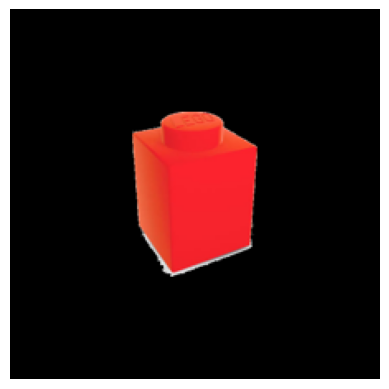

In [71]:
image = Image.open("brick.jpg").convert("RGB")

image_array = np.array(image)

# Replace white background with black
mask = np.all(image_array > 230, axis=2)
image_array[mask] = [0, 0, 0]

processed_image = Image.fromarray(image_array)

# Crop empty space
bbox = processed_image.getbbox()

if bbox is not None:
    processed_image = processed_image.crop(bbox)

# Reduce brick size
processed_image.thumbnail((100, 100))

# Create black background
canvas = Image.new("RGB", (224, 224), (0, 0, 0))

x = (224 - processed_image.width) // 2
y = (224 - processed_image.height) // 2

canvas.paste(processed_image, (x, y))

# Prepare model input
image_tensor = predict_transform(canvas).unsqueeze(0).to(device)

plt.imshow(canvas)
plt.axis("off")
plt.show()

## prepare legoClassifier_mini to deploy onto hugging face space
* LEGOClassifier/
* ├── app.py
* ├── requirements.txt
* ├── README.md
* ├── dataset_mapping_1.csv (dataset_mapping_2 is for training data only)
* ├── finetuning_functions/
    * ├── TransformForPrediction.py
    * └── model_builder.py
* └── models/
    * └── FineTuned_EffnetB0_full_dataset_10_epoch2.pth

In [2]:
%%writefile lego_classifier/app.py
import torch
import torch.nn as nn
import gradio as gr
import pandas as pd

from torchvision import models
from Pil import Image

from finetuning_functions.TransformForPrediction import transform_image

device = "cpu"

class_data=pd.read_csv("dataset_mapping_2.czsv")

class_names = dict(zip(class_data["class ID"], class_data["Class"]))

model = models.efficientnet_b0(weights=None)

model.classifier[1] = nn.Linear(
    in_features=model.classifier[1].in_features,
    out_features=14
)

model.load_state_dict(
    torch.load(
        "models/EfficientnetB0_50_epoch_model.pth",
        map_location=device,
        weights_only=True
    )
)

model = model.to(device)
model.eval()

def predict(image):

    # Preprocess uploaded image
    image_tensor = transform_image(image)

    image_tensor = image_tensor.unsqueeze(0).to(device)

    # Make prediction
    with torch.inference_mode():

        logits = model(image_tensor)

        probabilities = torch.softmax(logits, dim=1)[0]

    return {
        class_names[i]: probabilities[i].item()
        for i in range(len(probabilities))
    }


# Gradio interface
demo = gr.Interface(
    fn=predict,

    inputs=gr.Image(
        type="pil",
        label="Upload LEGO brick image"
    ),

    outputs=gr.Label(
        num_top_classes=3,
        label="Predicted LEGO brick"
    ),

    title="LEGO Brick Classifier",

    description="Identify 14 different types of LEGO bricks "
                "using a fine-tuned EfficientNet-B0 model."
)


if __name__ == "__main__":
    demo.launch()


Writing lego_classifier/app.py


In [11]:
import PIL
PIL.__version__

'13.0.0'

In [10]:
%%writefile lego_classifier/requirements.txt
torch=2.15.0
torchvision=0.29.2
gradio=6.32.0
numpy=2.5.4
pandas=3.1.1

Writing lego_classifier/requirements.txt
